How do truth-based errors respond to independent component noise and LOW/MEDIUM/HIGH density?

Controlled parameter-recovery sensitivity for the unchanged circular Gaussian truth:
centre (0,0), Rc=85 km, psi0=250000 m²/s, Q=I. The reused velocity function
implements u=−∂ψ/∂y, v=∂ψ/∂x and Ω=−2ψ0/Rc². U_ref is the maximum true vector speed,
evaluated by the original model, excluding perturbations. All settings are in
`rc3_config.json`; restart the kernel and run all cells.

The adapter loads `solo`/`doppio`/`latte` and `out_core_param_fit` unchanged from
`solo_idealised_tests_updated.ipynb`, `doppio_idealised_tests_updated.ipynb` and
`latte_idealised_tests.ipynb` under the configured manuscript source root's
`MOCA_PAPER/final_ESP_paper_notebooks/`. It reuses `gaussian_vel_reconstruction`,
`psi_params`, `axis_ratio_from_Q`, `tangential_velocity` and `unit_det` from
`modules/utils.py`. SI quantities are converted only at the original km-coordinate
fitting boundary. Both stages receive all observations, retaining the source's
internal finite-value/zero-projection filters, original optimiser settings and
validity checks. SOLO's original core_thresh=30000 in backend km units is retained;
it covers the complete transect. Angular-velocity errors use final outer-fit
`omega_s`, not preliminary `omega_inner_s`. SOLO shape is fixed, not estimated.

SOLO and DOPPIO transects pass through the true centre and span ±1.2 Rc. LATTE
uses stratified random D4 symmetry groups inside radius 1.2 Rc: eight-point
orbits plus four-point axis groups and one centre observation, invariant under
90° rotations and both coordinate-axis reflections. Inner/outer counts are
exactly (9,12), (33,28), (117,84), matching DOPPIO outer counts. There are no
boundary anchors. Seed pools are nested by stratum; input ordering is centre,
inner eight-point groups, inner axis groups, outer eight-point groups, outer
axis groups. Lower-density point sets are nested, not necessarily array prefixes.
Velocity perturbations remain independent at every unique point; noise is not
rotated, reflected or symmetrised. The same immutable coordinates supply the experiments and
supplements. N_outer counts unique observations with true rho > Rc/√2; this is an
experimental sampling constraint, not a recommended general ESP threshold.
No geometry or optimiser is tuned by recovery results. Preserve baseline bias
and extreme accepted estimates; numerical convergence does not establish accuracy.
These tests do not equalise observation budgets or justify a universal method ranking.

Noise SD/U_ref = 0, 2.5, 5, 10%; 100 independent replicates per nonzero condition;
one deterministic clean fit per method/density. Standard-normal draws are paired
across amplitudes. Locations are fixed. At DOPPIO's shared intersection, one
vector-noise draw is reused by both transects. No background current. The only
main results figure has method rows and centre/final Ω/α/Rc columns; bands are
10th–90th Monte Carlo percentiles of accepted errors, not confidence intervals.
Full accepted/attempted counts and failure statuses are reported separately.

In [1]:
from pathlib import Path
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/rc3-mpl")
import sys
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

WORKDIR = Path.cwd()
if not (WORKDIR / "rc3_validation.py").is_file():
    WORKDIR = WORKDIR / "esp/os_paper_additional_tests"
sys.path.insert(0, str(WORKDIR.resolve()))
from rc3_validation import (load_config, prepare_experiment, run_self_tests,
    run_noise_sampling, run_background_flow, sampling_summary, summarize,
    acceptance_table, interpretation, save_results)
from rc3_plotting import (plot_noise_sampling, plot_background_flow,
    plot_noise_geometry, save_figure)

CONFIG = load_config(WORKDIR / "rc3_config.json")
context = prepare_experiment(CONFIG)
checks = run_self_tests(context)
print("Self-tests:", ", ".join(checks["checks"]))
print(f"Common true U_ref = {context.truth['u_ref_m_s']:.6f} m/s; final true Ω = {context.truth['omega_s']:.8g} s⁻¹")

Self-tests: centred extents, unique/outer counts, one DOPPIO intersection, nested D4 LATTE strata, exact LATTE inner/outer counts, 90-degree rotations and axis reflections, unchanged preceding-revision transects, identical HIGH coordinates, error definitions, final outer Omega and units, streamfunction derivative signs, common true U_ref, finite accepted clean fits
Common true U_ref = 2.522835 m/s; final true Ω = -6.9204152e-05 s⁻¹


In [2]:
results = run_noise_sampling(context, checks)
summary = summarize(results)

In [3]:
display(sampling_summary(context).round(0))
display(acceptance_table(results))
print("Every attempted fit, including failures, is retained in results and the trial CSV.")
print(results.groupby(["method", "status"], sort=False).size().to_string())
print(f"Accepted {results.success.sum()}/{len(results)} full fits.")
if not results.success.all():
    display(results.loc[~results.success, ["method", "density", "noise_fraction",
        "background_fraction", "background_direction", "replicate", "status", "optimizer_message"]])
display(pd.DataFrame(checks["clean_high_baselines"]).round(4))
print("Noiseless LATTE errors at every density (unrounded values retained in CSV):")
display(results.loc[(results.method == "LATTE") & (results.noise_fraction == 0),
    ["density", "centre_error_km", "omega_error_pct", "alpha_error_pct", "rc_error_pct"]])

,method,density,n_per_transect,n_unique,n_inner_true,n_outer_true
0,SOLO,LOW,NaN,11,5,6
1,SOLO,MEDIUM,NaN,31,17,14
2,SOLO,HIGH,NaN,101,59,42
3,DOPPIO,LOW,11.0,21,9,12
4,DOPPIO,MEDIUM,31.0,61,33,28
5,DOPPIO,HIGH,101.0,201,117,84
6,LATTE,LOW,NaN,21,9,12
7,LATTE,MEDIUM,NaN,61,33,28
8,LATTE,HIGH,NaN,201,117,84


noise_fraction 0.000    0.025    0.050    0.100
method density                                 
SOLO   LOW       1/1  100/100  100/100  100/100
       MEDIUM    1/1  100/100  100/100  100/100
       HIGH      1/1  100/100  100/100  100/100
DOPPIO LOW       1/1  100/100  100/100  100/100
       MEDIUM    1/1  100/100  100/100  100/100
       HIGH      1/1  100/100  100/100  100/100
LATTE  LOW       1/1  100/100  100/100  100/100
       MEDIUM    1/1  100/100  100/100  100/100
       HIGH      1/1  100/100  100/100  100/100

Every attempted fit, including failures, is retained in results and the trial CSV.
method  status
SOLO    ok        903
DOPPIO  ok        903
LATTE   ok        903
Accepted 2709/2709 full fits.


,method,centre_error_km,omega_error_pct,alpha_error_pct,rc_error_pct
0,SOLO,0.0,0.0,NaN,0.0
1,DOPPIO,0.0,0.0,0.0,0.0
2,LATTE,0.0,0.0,0.0,0.0


Noiseless LATTE errors at every density (unrounded values retained in CSV):


,density,centre_error_km,omega_error_pct,alpha_error_pct,rc_error_pct
1806,LOW,4.610881e-16,1.958340e-14,0.0,0.000000e+00
2107,MEDIUM,1.499135e-15,0.000000e+00,0.0,2.220446e-14
2408,HIGH,7.652312e-16,4.895850e-13,0.0,1.998401e-13


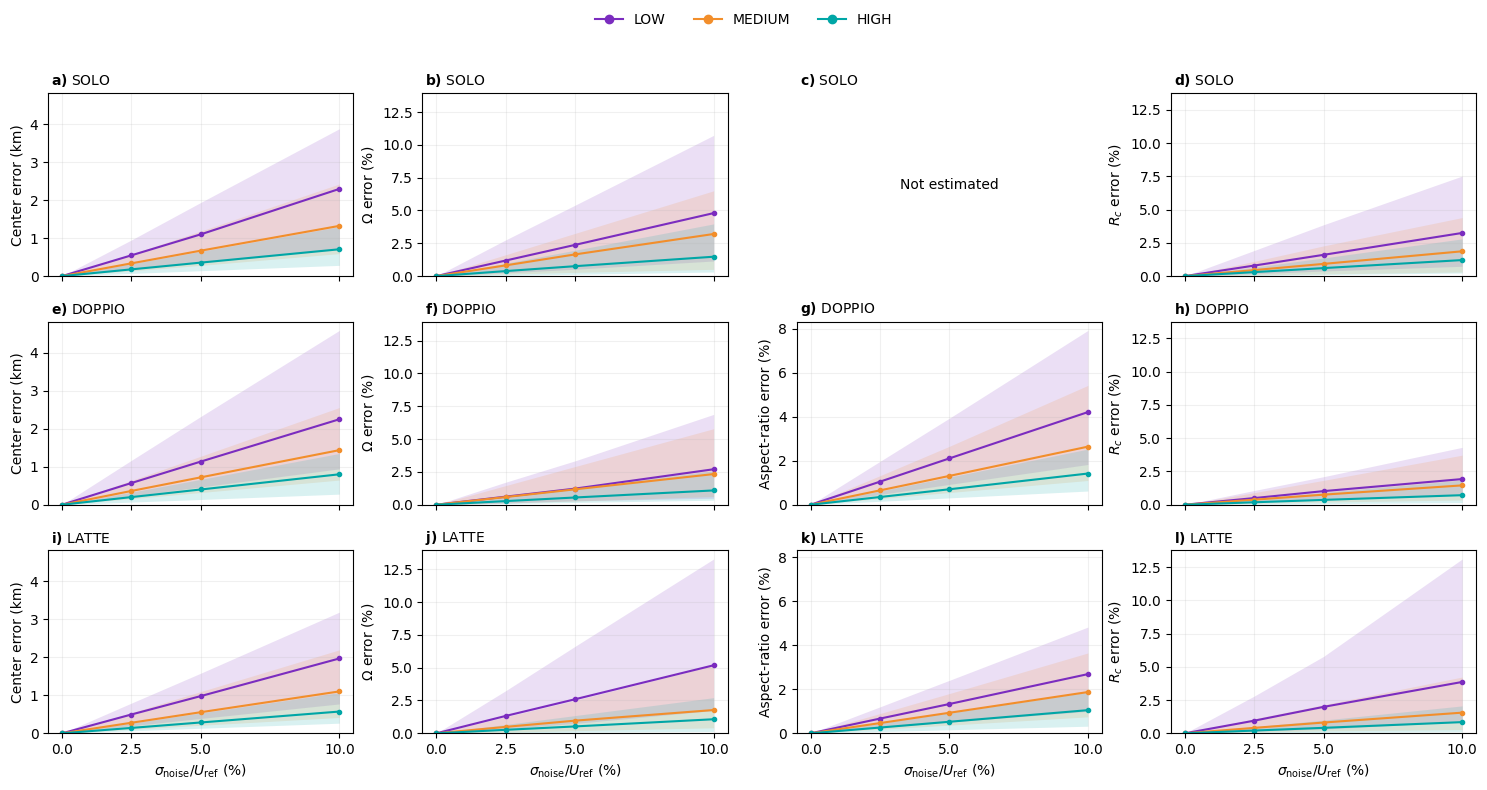

In [4]:
assert not plt.get_fignums()
fig = plot_noise_sampling(results, CONFIG)
main_paths = save_figure(fig, CONFIG.output / "rc3_noise_sampling", CONFIG)
display(fig)
plt.close(fig)

In [5]:
# Supplementary geometry is saved, not displayed as another main results figure.
supplement = plot_noise_geometry(context)
geometry_paths = save_figure(supplement, CONFIG.supplementary_output / "rc3_noise_sampling_geometry", CONFIG)
plt.close(supplement)
save_results(results, context, {"main_"+k: v for k, v in main_paths.items()} |
             {"supplement_"+k: v for k, v in geometry_paths.items()})
display(Markdown("Saved supplementary S1 (3×3 density geometries): " + str(geometry_paths["png"])))
display(Markdown(interpretation(results)))

Saved supplementary S1 (3×3 density geometries): /home/z5297792/UNSW-PhD/esp/os_paper_additional_tests/results/rc3_noise_sampling_geometry.png

- SOLO clean HIGH baseline: centre 0.000 km; final Ω 0%; Rc 0% absolute error.
- DOPPIO clean HIGH baseline: centre 0.000 km; final Ω 0%; Rc 0% absolute error.
- LATTE clean HIGH baseline: centre 0.000 km; final Ω 4.9e-13%; Rc 2e-13% absolute error.
- Accepted 2709/2709 full fits. Failure statuses: none. Acceptance is numerical validity, not an accuracy or identifiability guarantee.
- Largest retained accepted-fit Rc error: 24.89%; no error-based trimming is applied.

These fixed-geometry circular-Gaussian tests do not establish an unconditional method ranking or robustness to correlated errors, shear, temporal evolution, non-Gaussian eddies or platform-specific observation errors.